# Batch - 07
Solar Cell Dataset Analysis and Anomaly Detection

## Gathering Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import IsolationForest
import shap
import warnings 
warnings.filterwarnings('ignore')

c:\Users\dsair\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset Loading and Initial Overview

In this step, we load the dataset and examine its basic structure, including the number of rows and columns, feature names, and a preview of the data.

In [2]:
df = pd.read_csv("solardataset.csv")

print("Shape of dataset:", df.shape)
print("\nColumns:\n", df.columns)

df.head()

Shape of dataset: (42443, 30)

Columns:
 Index(['Cell_stack_sequence', 'Cell_architecture', 'Substrate_stack_sequence',
       'ETL_stack_sequence', 'ETL_deposition_procedure',
       'Perovskite_composition_a_ions', 'Perovskite_composition_b_ions',
       'Perovskite_composition_c_ions', 'Perovskite_composition_short_form',
       'Perovskite_additives_compounds', 'Perovskite_additives_concentrations',
       'Perovskite_thickness',
       'Perovskite_deposition_number_of_deposition_steps',
       'Perovskite_deposition_procedure', 'Perovskite_deposition_solvents',
       'Perovskite_deposition_quenching_induced_crystallisation',
       'Perovskite_deposition_thermal_annealing_temperature',
       'Perovskite_deposition_thermal_annealing_time', 'HTL_stack_sequence',
       'HTL_deposition_procedure', 'Backcontact_stack_sequence',
       'Backcontact_thickness_list', 'Backcontact_deposition_procedure',
       'Encapsulation', 'Encapsulation_stack_sequence', 'JV_measured',
       'JV_de

,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,Perovskite_additives_compounds,...,Backcontact_stack_sequence,Backcontact_thickness_list,Backcontact_deposition_procedure,Encapsulation,Encapsulation_stack_sequence,JV_measured,JV_default_Voc,JV_default_Jsc,JV_default_FF,JV_default_PCE
0,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,I,CsSnI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.002,0.22,0.57,0.00
1,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.120,0.49,0.25,0.00
2,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.135,3.69,0.26,0.13
3,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.227,1.32,0.41,0.12
4,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br,CsSnBr,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.190,1.57,0.34,0.10


## Data Structure and Data Types

This step examines the structure of the dataset, including data types, non-null values, and overall memory usage. It helps identify missing values and understand the nature of each feature.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42443 entries, 0 to 42442
Data columns (total 30 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Cell_stack_sequence                                      42443 non-null  object 
 1   Cell_architecture                                        42443 non-null  object 
 2   Substrate_stack_sequence                                 42443 non-null  object 
 3   ETL_stack_sequence                                       42443 non-null  object 
 4   ETL_deposition_procedure                                 42443 non-null  object 
 5   Perovskite_composition_a_ions                            42414 non-null  object 
 6   Perovskite_composition_b_ions                            42438 non-null  object 
 7   Perovskite_composition_c_ions                            42438 non-null  object 
 8   Perovskite_composition_sho

## Missing Value Analysis

This step identifies missing values across all features to understand data quality and determine appropriate cleaning strategies.

In [4]:
df.isnull().sum().sort_values(ascending=False)

Perovskite_additives_concentrations                        37547
Perovskite_thickness                                       29126
Perovskite_additives_compounds                             28672
Backcontact_thickness_list                                  7974
JV_default_FF                                               2286
JV_default_Voc                                              2134
JV_default_Jsc                                              2099
JV_default_PCE                                               924
Perovskite_composition_a_ions                                 29
Perovskite_composition_b_ions                                  5
Perovskite_composition_c_ions                                  5
ETL_deposition_procedure                                       0
Substrate_stack_sequence                                       0
ETL_stack_sequence                                             0
Perovskite_deposition_procedure                                0
Perovskite_deposition_num

## Handling Missing Values

Missing values in critical performance metrics are removed, while minor missing values in composition-related features are handled using appropriate imputation strategies.

In [5]:
df = df.dropna(subset=['JV_default_PCE'])

df = df.dropna(subset=[
    'JV_default_Voc',
    'JV_default_Jsc',
    'JV_default_FF'
])

df['Perovskite_composition_a_ions'] = df['Perovskite_composition_a_ions'].fillna('Unknown')
df['Perovskite_composition_b_ions'] = df['Perovskite_composition_b_ions'].fillna('Unknown')
df['Perovskite_composition_c_ions'] = df['Perovskite_composition_c_ions'].fillna('Unknown')

## Data Type Conversion and Final Missing Value Handling

Numerical features stored as text are converted into appropriate numeric formats. Remaining missing values are handled using median imputation to ensure a fully clean dataset.

In [6]:
df['Perovskite_deposition_thermal_annealing_temperature'] = pd.to_numeric(
    df['Perovskite_deposition_thermal_annealing_temperature'], errors='coerce'
)

df['Perovskite_deposition_thermal_annealing_time'] = pd.to_numeric(
    df['Perovskite_deposition_thermal_annealing_time'], errors='coerce'
)

df['Perovskite_deposition_thermal_annealing_temperature'].fillna(
    df['Perovskite_deposition_thermal_annealing_temperature'].median(),
    inplace=True
)

df['Perovskite_deposition_thermal_annealing_time'].fillna(
    df['Perovskite_deposition_thermal_annealing_time'].median(),
    inplace=True
)

# Drop high-missing irrelevant columns
df = df.drop([
    'Perovskite_additives_compounds',
    'Perovskite_additives_concentrations',
    'Perovskite_thickness',
    'Backcontact_thickness_list'
], axis=1)

df.isnull().sum().sum()

np.int64(0)

## Exploratory Data Analysis: Device Structure

This step analyzes key device structure features such as cell architecture, encapsulation, and substrate to understand their relationship with solar cell performance.

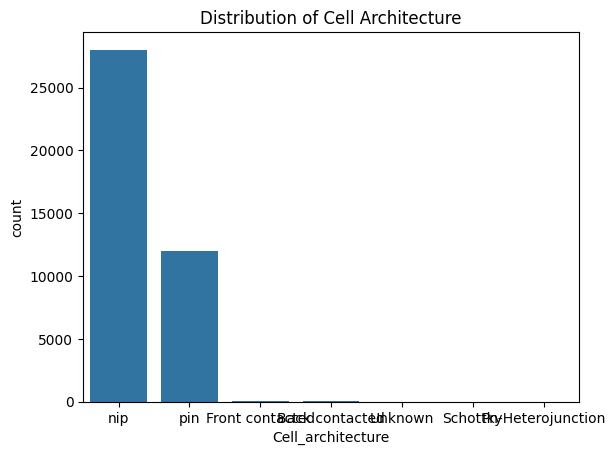

In [53]:
sns.countplot(x='Cell_architecture', data=df)
plt.title("Distribution of Cell Architecture")
plt.show()

## Cell Architecture vs Performance

This visualization examines how different cell architectures influence the power conversion efficiency (PCE) of solar cells.

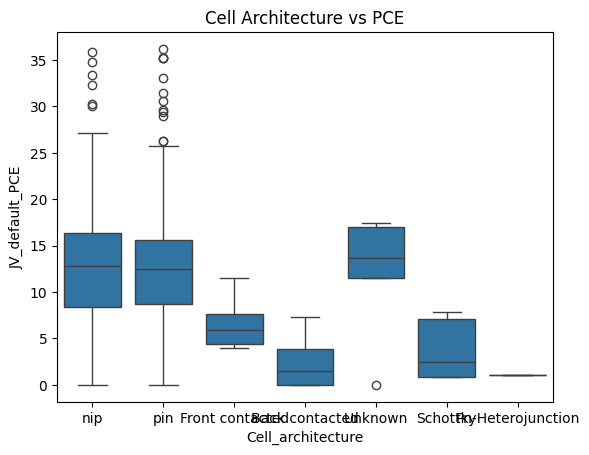

In [54]:
sns.boxplot(x='Cell_architecture', y='JV_default_PCE', data=df)
plt.title("Cell Architecture vs PCE")
plt.show()

## Encapsulation vs Performance

This analysis evaluates whether encapsulation (protective sealing) has an impact on the efficiency of solar cells.

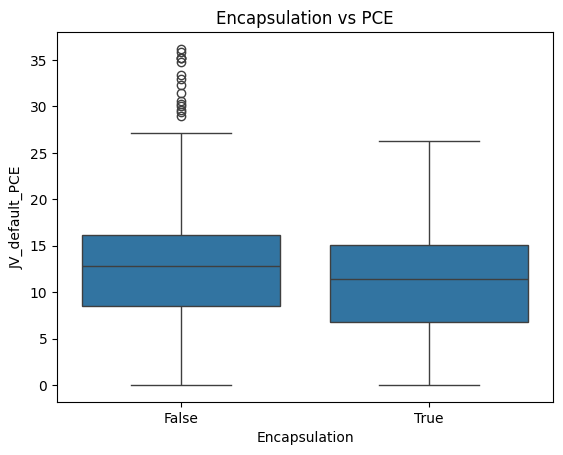

In [55]:
sns.boxplot(x='Encapsulation', y='JV_default_PCE', data=df)
plt.title("Encapsulation vs PCE")
plt.show()

## Substrate Analysis

This step analyzes the impact of the most common substrate types on solar cell performance.

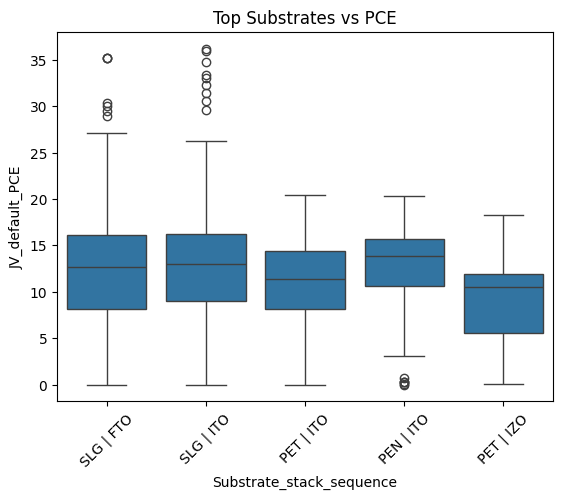

In [56]:
top_sub = df['Substrate_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='Substrate_stack_sequence',
    y='JV_default_PCE',
    data=df[df['Substrate_stack_sequence'].isin(top_sub)]
)

plt.xticks(rotation=45)
plt.title("Top Substrates vs PCE")
plt.show()

## Electron Transport Layer (ETL) Analysis

This step explores the most frequently used ETL materials and their impact on solar cell efficiency.

In [57]:
df['ETL_stack_sequence'].value_counts().head(10)

ETL_stack_sequence
TiO2-c | TiO2-mp              11068
TiO2-c                         6472
PCBM-60                        3056
PCBM-60 | BCP                  2522
SnO2-np                        1558
C60 | BCP                      1420
SnO2-c                         1297
TiO2-c | TiO2-mp | ZrO2-mp      614
ZnO-c                           462
PCBM-60 | C60 | BCP             420
Name: count, dtype: int64

## ETL Materials vs Performance

This visualization compares the top ETL materials and their influence on power conversion efficiency.

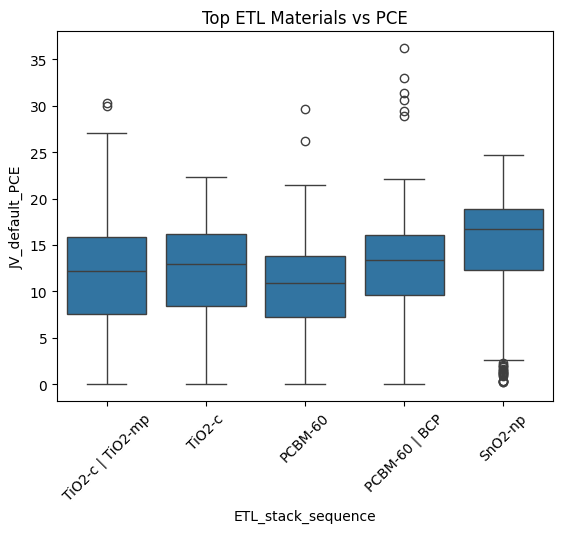

In [58]:
top_etl = df['ETL_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='ETL_stack_sequence',
    y='JV_default_PCE',
    data=df[df['ETL_stack_sequence'].isin(top_etl)]
)

plt.xticks(rotation=45)
plt.title("Top ETL Materials vs PCE")
plt.show()

## Perovskite Composition Analysis

This step examines the most common perovskite compositions used in the dataset to understand material distribution.

In [59]:
df['Perovskite_composition_short_form'].value_counts().head(10)

Perovskite_composition_short_form
MAPbI          25568
CsFAMAPbBrI     3376
FAMAPbBrI       2702
FAMAPbI          873
CsPbBrI          854
MAPbBrI          597
CsFAPbBrI        554
FAPbI            535
CsPbBr           426
CsPbI            421
Name: count, dtype: int64

## Perovskite Composition vs Performance

This visualization analyzes how different perovskite compositions affect the power conversion efficiency.

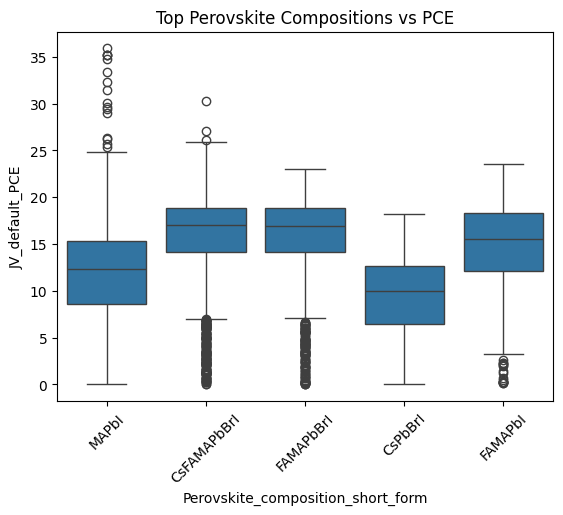

In [60]:
top_comp = df['Perovskite_composition_short_form'].value_counts().head(5).index

sns.boxplot(
    x='Perovskite_composition_short_form',
    y='JV_default_PCE',
    data=df[df['Perovskite_composition_short_form'].isin(top_comp)]
)

plt.xticks(rotation=45)
plt.title("Top Perovskite Compositions vs PCE")
plt.show()

## Annealing Temperature vs Performance

This plot explores the relationship between annealing temperature and solar cell efficiency.

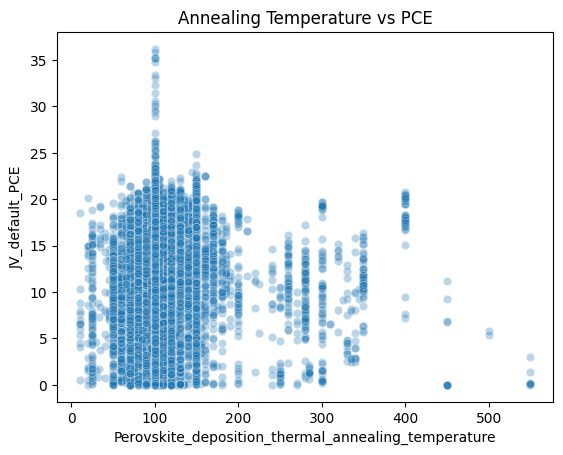

In [61]:
sns.scatterplot(
    x='Perovskite_deposition_thermal_annealing_temperature',
    y='JV_default_PCE',
    data=df,
    alpha=0.3
)

plt.title("Annealing Temperature vs PCE")
plt.show()

## Annealing Time vs Performance

This visualization examines how annealing duration influences the efficiency of solar cells.

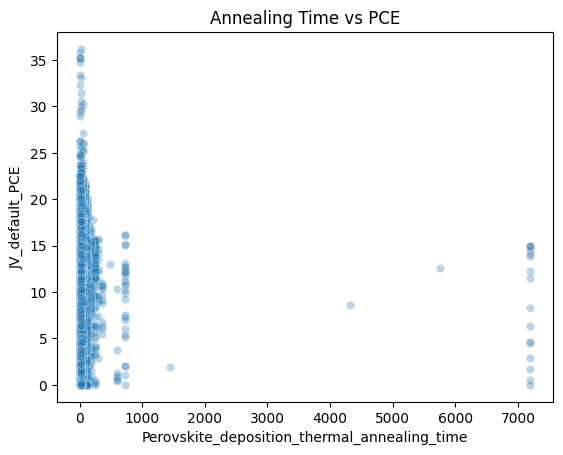

In [62]:
sns.scatterplot(
    x='Perovskite_deposition_thermal_annealing_time',
    y='JV_default_PCE',
    data=df,
    alpha=0.3
)

plt.title("Annealing Time vs PCE")
plt.show()

## Hole Transport Layer (HTL) Analysis

This step explores the most commonly used HTL materials in the dataset.

In [63]:
df['HTL_stack_sequence'].value_counts().head(10)

HTL_stack_sequence
Spiro-MeOTAD    19776
PEDOT:PSS        6145
none             2511
PTAA             1720
NiO-c            1589
P3HT              832
NiO-np            375
CuSCN             213
NiMgLiO           152
NiO               148
Name: count, dtype: int64

## HTL Materials vs Performance

This visualization compares the top HTL materials and their effect on solar cell efficiency.

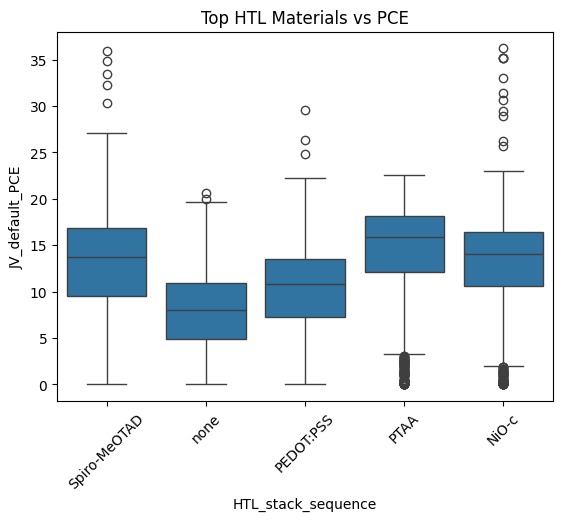

In [64]:
top_htl = df['HTL_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='HTL_stack_sequence',
    y='JV_default_PCE',
    data=df[df['HTL_stack_sequence'].isin(top_htl)]
)

plt.xticks(rotation=45)
plt.title("Top HTL Materials vs PCE")
plt.show()

## Back Contact Analysis

This step explores the most commonly used back contact materials in solar cells.

In [65]:
df['Backcontact_stack_sequence'].value_counts().head(10)

Backcontact_stack_sequence
Au           19328
Ag           12322
Al            2943
Carbon        2031
MoO3 | Ag      614
Cu             485
Ca | Al        288
MoO3 | Al      115
MoO3 | Au      114
AgAl            77
Name: count, dtype: int64

## Back Contact vs Performance

This visualization analyzes how different back contact materials influence solar cell efficiency.

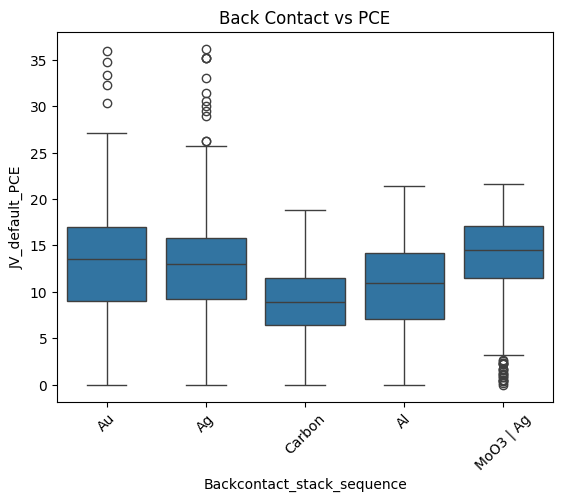

In [66]:
top_bc = df['Backcontact_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='Backcontact_stack_sequence',
    y='JV_default_PCE',
    data=df[df['Backcontact_stack_sequence'].isin(top_bc)]
)

plt.xticks(rotation=45)
plt.title("Back Contact vs PCE")
plt.show()

## Data Preparation for Modeling

In this step, irrelevant and redundant features are removed to simplify the dataset and prepare it for machine learning.

In [67]:
cols_to_drop = [
    'Cell_stack_sequence',
    'Substrate_stack_sequence',
    'Encapsulation_stack_sequence',
    'Perovskite_deposition_solvents'
]

df = df.drop(cols_to_drop, axis=1)

## Chemical Feature Engineering

The perovskite composition is decomposed into individual elemental features to better capture chemical information for modeling.

In [68]:
elements = ['Cs', 'FA', 'MA', 'Pb', 'Sn', 'Br', 'I']

for el in elements:
    df[el] = df['Perovskite_composition_short_form'].apply(lambda x: 1 if el in x else 0)

df = df.drop('Perovskite_composition_short_form', axis=1)

## Encoding Categorical Features

Categorical features are converted into numerical form using one-hot encoding to make them suitable for machine learning models.

In [69]:
df_encoded = pd.get_dummies(df, drop_first=True)

## Train-Test Split

The dataset is split into training and testing sets to evaluate model performance on unseen data.

In [70]:
X = df_encoded.drop('JV_default_PCE', axis=1)
y = df_encoded['JV_default_PCE']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Baseline Model Training

A Random Forest Regressor is used as a baseline model to predict power conversion efficiency (PCE).

In [71]:
model = RandomForestRegressor(
    n_estimators=30,
    max_depth=10,
    n_jobs=-1,
    random_state=42
)

model.fit(X_train, y_train)

,n_estimators,30
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Model Evaluation

The trained model is evaluated using RMSE and R² score to assess prediction performance.

In [72]:
y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 0.9461284093612188
R2 Score: 0.9674444073366056


## Handling Target Leakage

The initial model shows unusually high performance due to the presence of features directly related to the target (PCE). These leakage features are removed to build a realistic predictive model.

In [73]:
df_encoded = df_encoded.drop([
    'JV_default_Voc',
    'JV_default_Jsc',
    'JV_default_FF'
], axis=1)

## Retraining Model After Removing Leakage

The model is retrained after removing leakage features to obtain a realistic estimate of predictive performance.

In [74]:
X = df_encoded.drop('JV_default_PCE', axis=1)
y = df_encoded['JV_default_PCE']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 4.021676722593248
R2 Score: 0.4117800439192938


## Feature Importance Analysis

Feature importance is computed to identify the most influential factors affecting solar cell efficiency.

In [75]:
importances = model.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names)
feat_imp = feat_imp.sort_values(ascending=False)

feat_imp.head(20)

Perovskite_deposition_quenching_induced_crystallisation         0.273651
Pb                                                              0.191474
FA                                                              0.106078
I                                                               0.044256
Perovskite_deposition_procedure_Spin-coating >> Spin-coating    0.026274
HTL_stack_sequence_none                                         0.025739
Perovskite_composition_a_ions_FA; MA                            0.025721
HTL_stack_sequence_PEDOT:PSS                                    0.025018
HTL_deposition_procedure_Unknown                                0.019763
HTL_stack_sequence_PTAA                                         0.019275
MA                                                              0.016136
HTL_stack_sequence_Spiro-MeOTAD                                 0.013883
HTL_stack_sequence_P3HT                                         0.012732
Perovskite_composition_a_ions_MA                   

## Feature Selection

To improve model efficiency and reduce dimensionality, only the most important features are selected based on feature importance scores.

In [76]:
top_features = feat_imp.head(100).index

X_reduced = X[top_features]

## Model Training with Reduced Features

The model is retrained using only the most important features to improve efficiency and evaluate performance.

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 4.022418199307949
R2 Score: 0.41156312364585046


## Clustering Analysis

K-Means clustering is applied to identify groups of similar solar cell configurations based on their features.

In [78]:
kmeans = KMeans(n_clusters=5, random_state=42)

clusters = kmeans.fit_predict(X_reduced)

df['cluster'] = clusters

## Dimensionality Reduction for Visualization

Principal Component Analysis (PCA) is used to reduce the feature space to two dimensions for visualization of clusters.

In [79]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_reduced)

## Cluster Visualization

The clusters are visualized in a two-dimensional space using PCA to observe grouping patterns and separability.

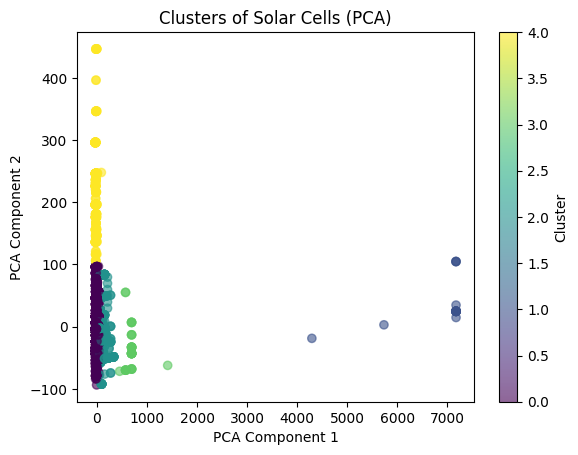

In [80]:
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap='viridis',
    alpha=0.6
)

plt.title("Clusters of Solar Cells (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

## Cluster-wise Performance Analysis

This step evaluates the average efficiency (PCE) for each cluster to understand which groups perform better.

In [81]:
df.groupby('cluster')['JV_default_PCE'].mean()

cluster
0    12.065807
1     8.961667
2    11.767594
3     8.110541
4     9.985675
Name: JV_default_PCE, dtype: float64

## Anomaly Detection

Isolation Forest is used to detect unusual or rare solar cell configurations that deviate from typical patterns.

In [82]:
iso = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

anomaly_labels = iso.fit_predict(X_reduced)

df['anomaly'] = anomaly_labels

## Anomaly Analysis

This step analyzes the distribution of anomalies and compares their performance with normal data points.

In [83]:
df['anomaly'].value_counts()

df.groupby('anomaly')['JV_default_PCE'].mean()

anomaly
-1     6.328567
 1    12.141299
Name: JV_default_PCE, dtype: float64

## Anomaly Visualization

Anomalies are visualized using PCA to observe how they differ from normal data points in feature space.

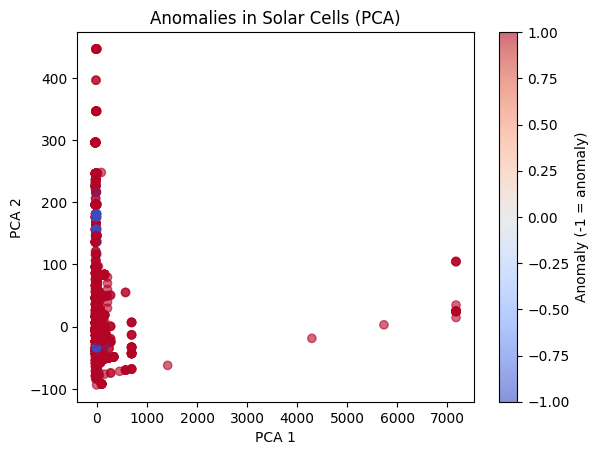

In [84]:
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['anomaly'],
    cmap='coolwarm',
    alpha=0.6
)

plt.title("Anomalies in Solar Cells (PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Anomaly (-1 = anomaly)")
plt.show()

## Model Explainability using SHAP

SHAP (SHapley Additive exPlanations) is used to interpret the model by quantifying the contribution of each feature to the prediction.

In [ ]:
X_train = X_train.astype(float)
X_test = X_test.astype(float)


explainer = shap.TreeExplainer(model)

X_sample = X_test.sample(300, random_state=42)

shap_values = explainer.shap_values(X_sample)

## Global Feature Importance (SHAP)

This plot shows the overall importance of features based on their contribution to model predictions.

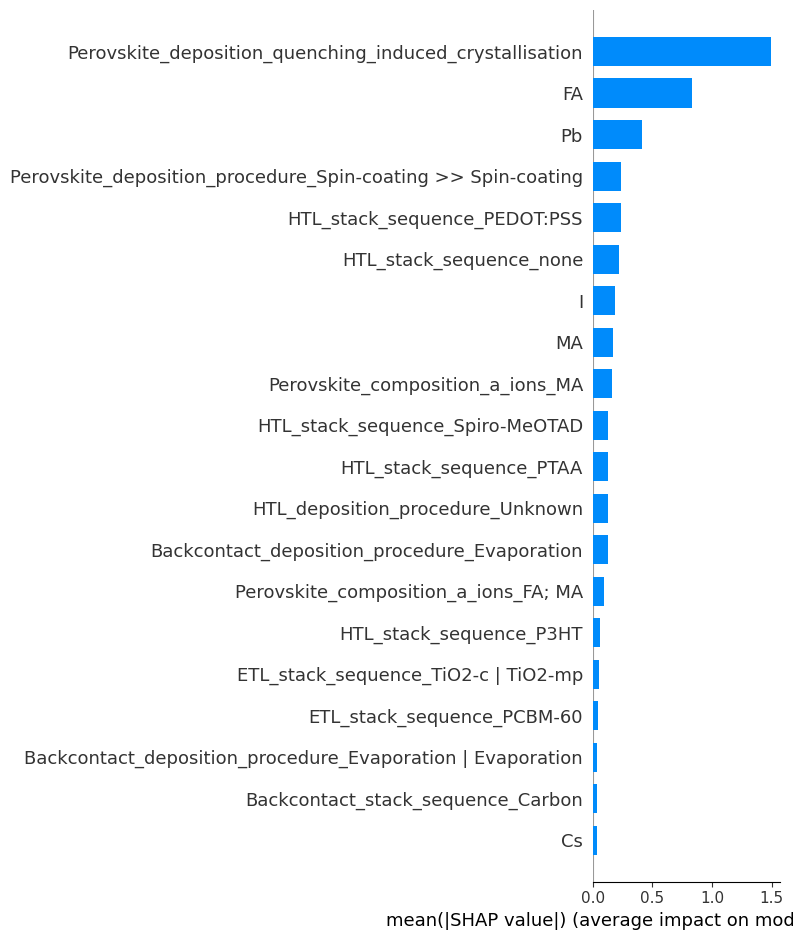

In [86]:
shap.summary_plot(shap_values, X_sample, plot_type="bar")

## SHAP Summary Plot

This visualization shows how each feature impacts the prediction across all samples, indicating whether it increases or decreases the predicted efficiency.

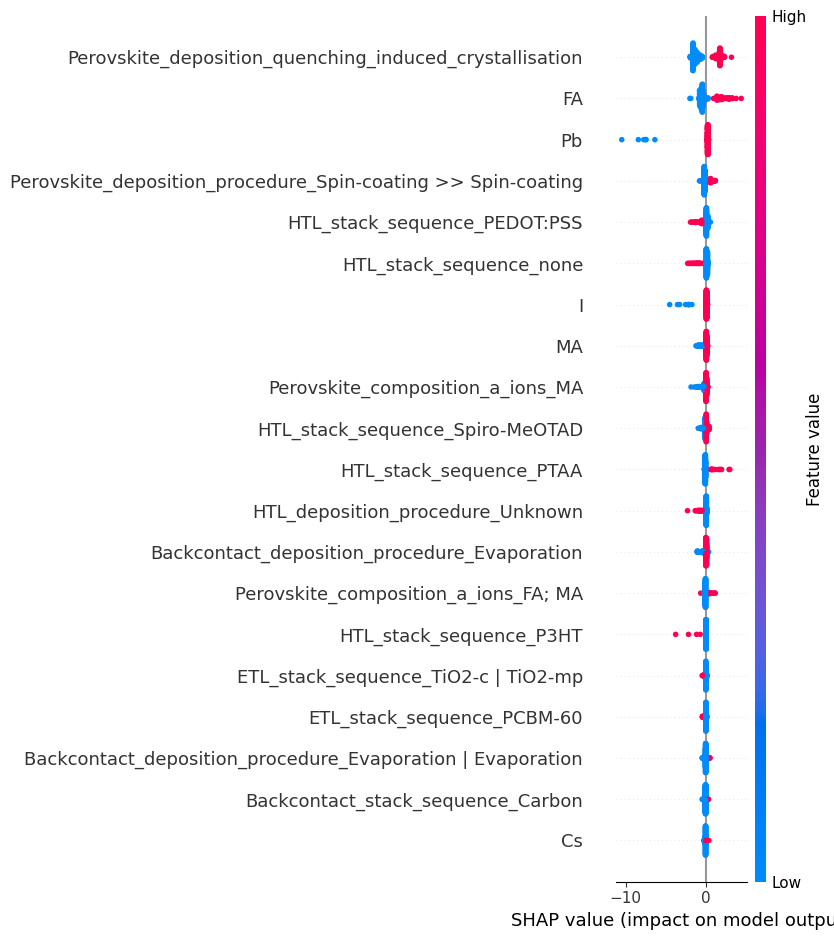

In [87]:
shap.summary_plot(shap_values, X_sample)